# Q8B — Aplicação da clusterização aos municípios paraenses

**Projeto:** ENEM — Pará (PA)  
**Período:** 2009–2023  
**Referência territorial:** município da escola (ESC)  
**Unidade de análise:** município por edição  
**Método:** K-Means\
**Fontes:** `painel`, `dsp` e `shape`.

**OBJETIVO**

Aplicar o método selecionado no notebook [`Q8A_CLUSTERINGS_METODO`](Q8A_CLUSTERINGS_METODO.ipynb)  ao conjutde municípios paraenses e caracterizar os perfis multidisciplinares identificados nas cinco áreas do ENEM.

A aplicação responde: **como os municípios paraenses se organizam em perfis semelhantes de desempenho multidisciplinar e como essa organização relativa se modifica entre 2009 e 2023?**

O K-Means é ajustado separadamente em cada edição, após padronização das cinco disciplinas dentro do respectivo ano. Assim, os perfis A e B representam posições relativas em cada edição; não são níveis absolutos fixos nem indicam, isoladamente, melhora ou piora histórica.

---
<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**\
Os rótulos originais atribuídos pelo K-Means não possuem significado ordinal e podem variar entre execuções e edições. Para garantir consistência interpretativa, os grupos foram ordenados anualmente pela média dos escores padronizados das cinco disciplinas, atribuindo o Perfil A ao grupo de maior desempenho relativo e o Perfil B ao de menor desempenho. Essa ordenação não altera a composição dos agrupamentos nem as métricas de validação.
</div>


### Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">
    
> **Dois perfis multidimensionais foram identificados**  
> O K-Means identificou dois grupos de municípios com posições relativas superiores e inferiores de desempenho, considerando simultaneamente as cinco disciplinas do ENEM

> **A diferenciação é consistente entre as disciplinas:**  
> O Perfil A apresentou médias superiores ao Perfil B nas cinco disciplinas e em todas as 15 edições. Redação registrou a maior diferença média entre os grupos, com 49,58 pontos.

> **A maioria dos municípios manteve sua classificação entre os extremos**  
> Dos 37 municípios analisados, 32 (86,5%) permaneceram no mesmo perfil entre 2009 e 2023, enquanto cinco (13,5%) mudaram de classificação.
 </div>

---



## 1. Configuração e dependências

O notebook reutiliza as rotinas de preparação e clusterização do módulo `src/utils/evolucao_perfil_municipal.py`. Não há redefinição de funções analíticas aqui.

In [26]:
from _setup2 import *

from utils.utils_ML import DISCIPLINAS_ENEM_2009,preparar_painel_municipal,ajustar_clusters_por_ano,resumir_transicoes_clusters
sns.set_theme(style="whitegrid", context="notebook")

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"
ANOS = list(range(2009, 2024))
ANO_INICIAL, ANO_FINAL = ANOS[0], ANOS[-1]
N_MINIMO_PARTICIPANTES = 100
K_ESCOLHIDO = 2
RANDOM_STATE = 42
N_INIT = 50
DISCIPLINAS = list(DISCIPLINAS_ENEM_2009)

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel = out["painel"]["data"].copy()
dsp = out["dsp"]["data"].copy()
shape = out["shape"]["data"].copy()


desempenho_municipal = eda2.preparar_desempenho_territorial_dsp(
    dsp,referencia=TIPO_REFERENCIA,n_minimo_participantes=N_MINIMO_PARTICIPANTES,
    anos_inicio_comparavel=2002,painel=painel)

painel_municipal = preparar_painel_municipal(desempenho_municipal,
    anos=ANOS,disciplinas=DISCIPLINAS,exigir_elegibilidade=True)

print("=" * 66)
print(f"UF           : {UF_PROCESSAMENTO}  | Período: {ANO_INICIAL}–{ANO_FINAL}| Referência: {TIPO_REFERENCIA} ")
print(f"MÉTODO       : K-Means | K={K_ESCOLHIDO}")
print(f"DISCIPLINAS  : {', '.join(DISCIPLINAS)}")
print(f"painel       : {painel.shape[0]:,} x {painel.shape[1]}".replace(",", "."))
print(f"dsp          : {dsp.shape[0]:,} x {dsp.shape[1]}".replace(",", "."))
print(f"shape        : {shape.shape[0]:,} x {shape.shape[1]}".replace(",", "."))
print("=" * 66)

UF           : PA  | Período: 2009–2023| Referência: ESC 
MÉTODO       : K-Means | K=2
DISCIPLINAS  : CH, CN, LC, MT, REDACAO
painel       : 3.625 x 82
dsp          : 250.436 x 17
shape        : 144 x 16


## 2. Balanceamento e Cobertura

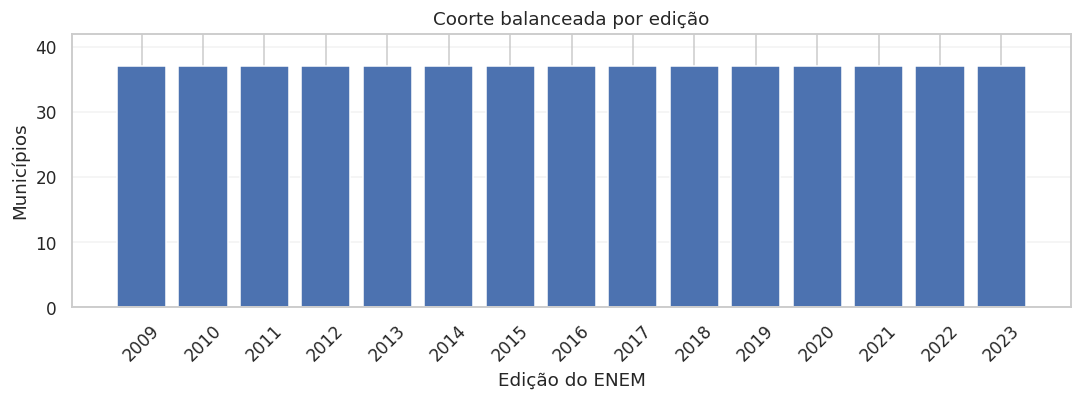

Coorte validada: 37 municípios × 15 edições = 555 observações.


In [3]:
municipios_por_ano = {
    ano: set(
        painel_municipal.loc[
            painel_municipal["ano"].eq(ano)
            & painel_municipal["media_geral_5_disciplinas"].notna(),
            "CO_MUNICIPIO_TERRITORIO",
        ]
    )
    for ano in ANOS
}
municipios_balanceados = set.intersection(*(municipios_por_ano[ano] for ano in ANOS))

painel_balanceado = painel_municipal.loc[
    painel_municipal["CO_MUNICIPIO_TERRITORIO"].isin(municipios_balanceados)
].copy()
painel_balanceado = painel_balanceado.sort_values(
    ["ano", "CO_MUNICIPIO_TERRITORIO"]
).reset_index(drop=True)

if len(municipios_balanceados) != 37 or len(painel_balanceado) != 555:
    raise ValueError(
        f"Coorte divergente: {len(municipios_balanceados)} municípios e "
        f"{len(painel_balanceado)} observações; esperado 37 e 555."
    )
if painel_balanceado.duplicated(["ano", "CO_MUNICIPIO_TERRITORIO"]).any():
    raise ValueError("Há duplicidade de município-ano na coorte.")

cobertura = painel_balanceado.groupby("ano").agg(
    municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
    observacoes=("CO_MUNICIPIO_TERRITORIO", "size"),
)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(cobertura.index.astype(str), cobertura["municipios"])
ax.set(title="Coorte balanceada por edição", xlabel="Edição do ENEM", ylabel="Municípios")
ax.set_ylim(0, 42)
ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Coorte validada: {len(municipios_balanceados)} municípios × {len(ANOS)} edições = {len(painel_balanceado)} observações.")

### Comentários

A análise longitudinal utiliza somente municípios com as cinco disciplinas disponíveis em todas as 15 edições. A interseção anual deve reproduzir os dados validado em [`Q8A_CLUSTERINGS_METODO`](Q8A_CLUSTERINGS_METODO.ipynb). Assim, totalizando 555 observações município-ano. Todos os municípios incluídos apresentam as cinco disciplinas válidas em todo o período analisado.

Esse balanceamento permite acompanhar o mesmo conjunto de municípios entre 2009 e 2023, reduzindo a influência de entradas e saídas na composição da amostra. Em contrapartida, os resultados representam exclusivamente os 37 municípios que atenderam simultaneamente aos critérios de elegibilidade e completude, não devendo ser generalizados automaticamente para todos os municípios paraenses.

## 3. Aplicação do K-Means (K=2)

O modelo é ajustado separadamente em cada edição. Em cada ano, as cinco disciplinas são padronizadas com `StandardScaler`; em seguida, o K-Means agrupa os 37 municípios. Os grupos são ordenados pela média geral das cinco disciplinas naquele ano: **Perfil A** representa a posição relativa superior e **Perfil B**, a inferior.

In [4]:
classificacao_clusters, diagnostico_clusters = ajustar_clusters_por_ano(
    painel_balanceado,
    anos=ANOS,
    disciplinas=DISCIPLINAS,
    k=K_ESCOLHIDO,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
)

# Inverte a nomenclatura dos perfis
classificacao_clusters["perfil_relativo"] = (
    classificacao_clusters["perfil_relativo"]
    .map({"Perfil A": "Perfil B", "Perfil B": "Perfil A"})
)

if classificacao_clusters.empty or classificacao_clusters["ano"].nunique() != len(ANOS):
    raise ValueError("A classificação não foi produzida para todas as 15 edições.")

if classificacao_clusters.groupby("ano")["CO_MUNICIPIO_TERRITORIO"].nunique().ne(37).any():
    raise ValueError("Alguma edição não contém os 37 municípios esperados.")

## 4. Qualidade da separação por edição

A silhouette é apresentada como diagnóstico da separação e coesão dos grupos em cada edição. Ela não deve ser interpretada isoladamente nem como medida de desempenho educacional.

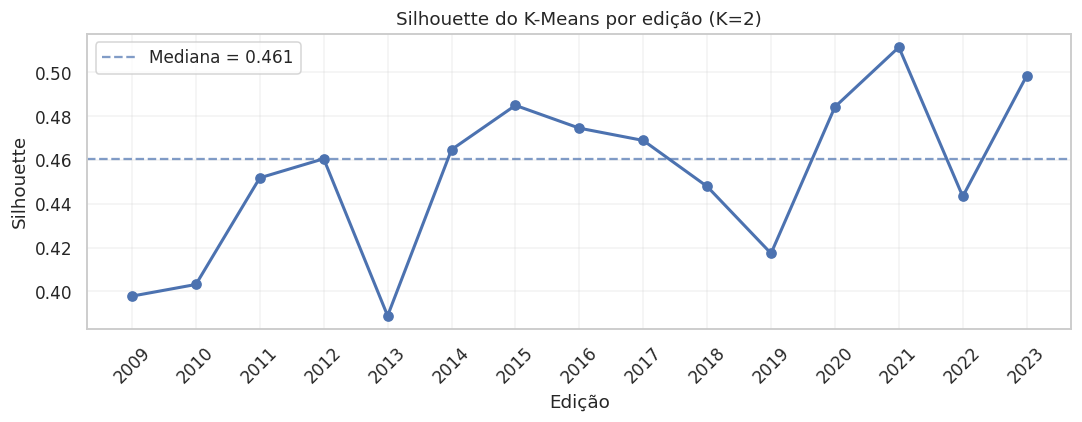

In [5]:
silhouette_anual = (
    diagnostico_clusters[["ano", "silhouette"]]
    .drop_duplicates("ano")
    .sort_values("ano")
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(silhouette_anual["ano"], silhouette_anual["silhouette"], marker="o", linewidth=2)
ax.axhline(silhouette_anual["silhouette"].median(), linestyle="--", alpha=.7,
           label=f"Mediana = {silhouette_anual['silhouette'].median():.3f}")
ax.set(title="Silhouette do K-Means por edição (K=2)", xlabel="Edição", ylabel="Silhouette")
ax.set_xticks(ANOS)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

### Comentários

A silhouette apresentou média de **0,4533** e mediana de **0,4606** nas 15 edições. Os valores variaram de **0,3889 em 2013** a **0,5116 em 2021**, indicando que o grau de coesão e separação dos dois grupos não foi idêntico ao longo do período.

A variação anual é compatível com a natureza da aplicação: o K-Means é ajustado separadamente em cada edição, utilizando a distribuição relativa dos 37 municípios daquele ano. A silhouette funciona, portanto, como diagnóstico da estrutura encontrada em cada edição, e não como medida de desempenho educacional ou evidência isolada de que os grupos sejam naturais.

## 5. Tamanho e composição dos perfis

A distribuição anual mostra quantos municípios foram classificados em cada perfil. Como o K-Means é ajustado separadamente por edição, os tamanhos podem variar de um ano para outro.

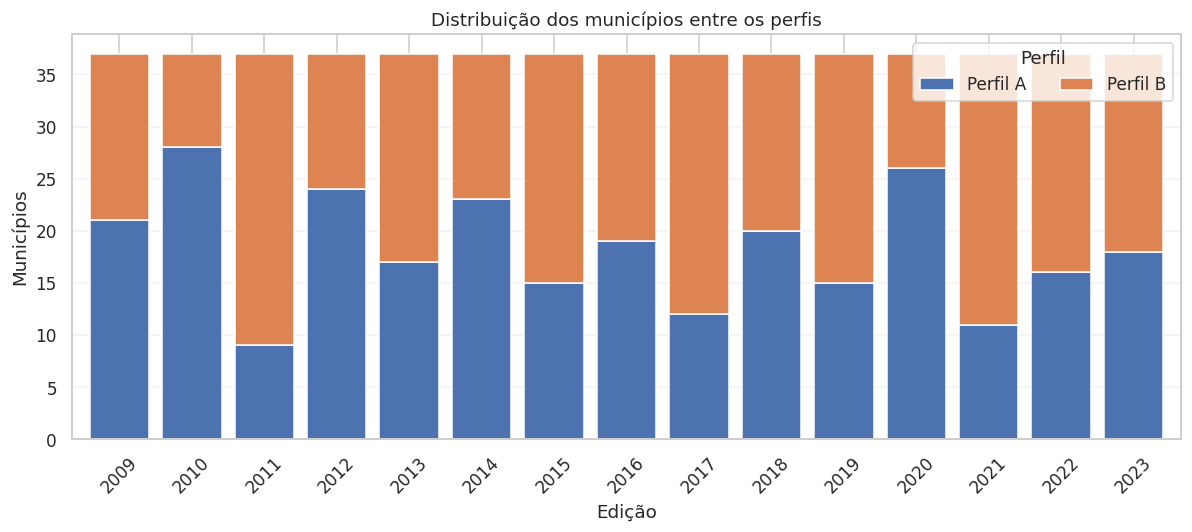

In [6]:
distribuicao_perfis = (
    classificacao_clusters.groupby(["ano", "perfil_relativo"])
    .agg(n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"))
    .reset_index()
)

pivot_tamanhos = distribuicao_perfis.pivot(
    index="ano", columns="perfil_relativo", values="n_municipios"
).reindex(index=ANOS)

fig, ax = plt.subplots(figsize=(11, 5))
pivot_tamanhos.plot(kind="bar", stacked=True, ax=ax, width=.82)
ax.set(title="Distribuição dos municípios entre os perfis", xlabel="Edição", ylabel="Municípios")
ax.legend(title="Perfil", ncol=2)
ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Comentários 

A composição dos perfis variou entre as edições, embora a coorte permaneça fixa em 37 municípios.O Perfil A reuniu entre 9 e 28 municípios, enquanto o Perfil B também variou entre 9 e 28 municípios

As maiores assimetrias ocorreram em 2010, quando os grupos reuniram 28 e 9 municípios, respectivamente; em 2011, com 9 e 28; e em 2021, com 11 e 26. Em 2023, a distribuição foi mais equilibrada, com 19 municípios no Perfil A e 18 no Perfil B.Essas diferenças refletem a formação anual dos agrupamentos, e não mudanças na quantidade de municípios analisados. Também reforçam que os perfis são relativos a cada edição e que seus tamanhos não permanecem fixos ao longo do tempo.

## 6. Caracterização multidisciplinar dos perfis


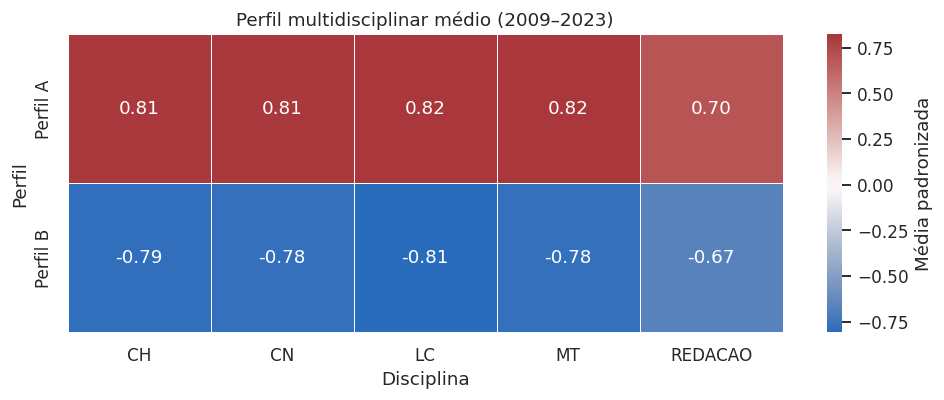

In [7]:
painel_z = painel_balanceado[["ano", "CO_MUNICIPIO_TERRITORIO", "NO_MUNICIPIO_TERRITORIO"] + DISCIPLINAS].copy()
for disciplina in DISCIPLINAS:
    painel_z[f"{disciplina}_z"] = painel_z.groupby("ano")[disciplina].transform(
        lambda serie: (serie - serie.mean()) / serie.std(ddof=0)
    )

classificacao_z = classificacao_clusters.merge(
    painel_z[["ano", "CO_MUNICIPIO_TERRITORIO"] + [f"{d}_z" for d in DISCIPLINAS]],
    on=["ano", "CO_MUNICIPIO_TERRITORIO"],
    how="left",
    validate="one_to_one",
)

colunas_z = [f"{d}_z" for d in DISCIPLINAS]
perfil_z_anual = (
    classificacao_z.groupby(["ano", "perfil_relativo"])[colunas_z]
    .mean()
    .reset_index()
)
perfil_z_geral = perfil_z_anual.groupby("perfil_relativo")[colunas_z].mean()
perfil_z_geral.columns = DISCIPLINAS

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(
    perfil_z_geral,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="vlag",
    linewidths=.5,
    cbar_kws={"label": "Média padronizada"},
    ax=ax,
)
ax.set(title="Perfil multidisciplinar médio (2009–2023)", xlabel="Disciplina", ylabel="Perfil")
plt.tight_layout()
plt.show()

### Comentários

O mapa de calor evidencia uma separação multidisciplinar: considerando a média dos escores padronizados ao longo das 15 edições, o Perfil B apresentou valores negativos nas cinco disciplinas, enquanto o Perfil A apresentou valores positivos.

No Perfil B, as médias padronizadas foram aproximadamente −0,78 em CH, −0,78 em CN, −0,81 em LC, −0,78 em MT e −0,67 em Redação. No Perfil A, foram +0,81 em CH, +0,81 em CN, +0,82 em LC, +0,82 em MT e +0,70 em Redação.

A distinção entre os perfis, portanto, não está concentrada em uma única disciplina: os cinco componentes contribuem para a diferenciação multidimensional. Esses valores representam posições relativas dentro de cada edição, pois a padronização é realizada anualmente; não devem ser interpretados como evolução absoluta das notas entre 2009 e 2023.

## 7. Notas originais por disciplina e perfil

A seguir, as médias em pontos ENEM complementam os escores padronizados. As médias são calculadas por edição e perfil, preservando a unidade original de cada disciplina.

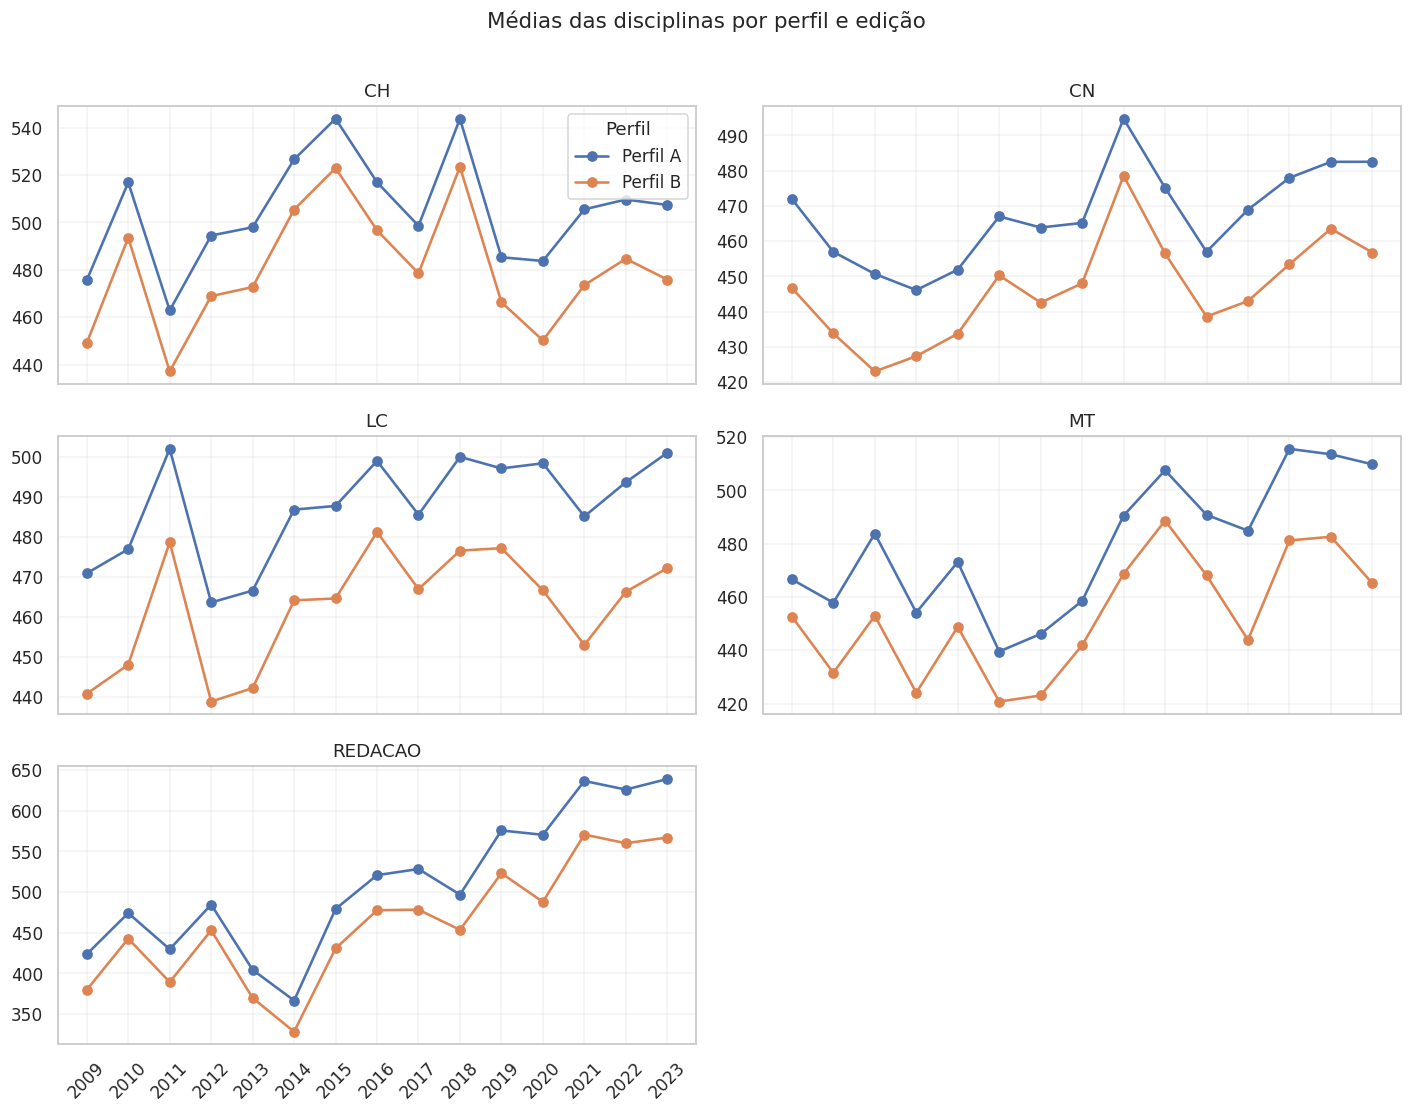

In [8]:
perfil_notas = (
    classificacao_clusters.groupby(["ano", "perfil_relativo"])[DISCIPLINAS]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
for disciplina, ax in zip(DISCIPLINAS, axes.flat):
    for perfil, grupo in perfil_notas.groupby("perfil_relativo"):
        ax.plot(grupo["ano"], grupo[disciplina], marker="o", linewidth=1.7, label=perfil)
    ax.set_title(disciplina)
    ax.grid(alpha=.25)
    ax.set_xticks(ANOS)
    ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
axes[0, 0].legend(title="Perfil")
fig.suptitle("Médias das disciplinas por perfil e edição", y=1.01, fontsize=14)
fig.tight_layout()
plt.show()

### Comentários

As médias em pontos ENEM complementam a leitura dos escores padronizados. Em todas as 15 edições e nas cinco disciplinas, o Perfil A apresentou média superior à do Perfil B.

Considerando a diferença média entre os perfis ao longo das edições, as maiores distâncias foram observadas em Redação (49,58 pontos) e Matemática (26,56 pontos), seguidas por Linguagens (25,14), Ciências Humanas (24,66) e Ciências da Natureza (21,11).

Essas diferenças descrevem a composição dos grupos em cada edição. Como o K-Means é reajustado anualmente, os municípios podem mudar de perfil; assim, as curvas não representam trajetórias de uma população fixa de municípios em cada grupo. A comparação temporal deve considerar simultaneamente a variação das notas e a reclassificação anual.

## 8. Transição dos municípios entre 2009 e 2023

A matriz de transição compara o perfil relativo atribuído a cada município nos extremos do período. A diagonal representa municípios que permaneceram no mesmo perfil; as células fora da diagonal representam mudanças de posição relativa.

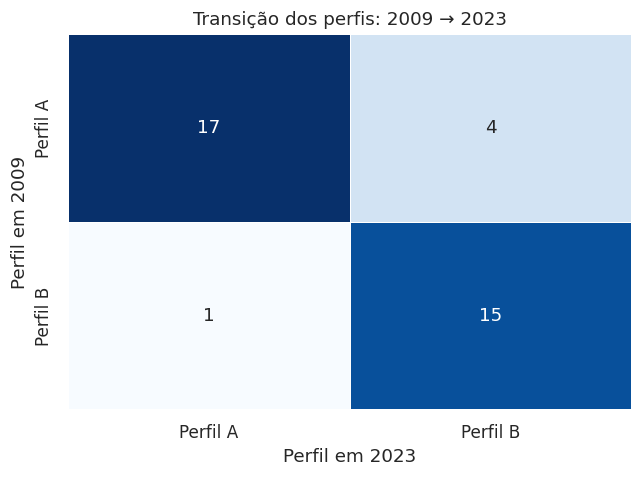

Municípios comparáveis: 37
Permaneceram no perfil: 32 (86.5%)
Mudaram de perfil: 5 (13.5%)
Municípios que mudaram de perfil: 5 de 37
NO_MUNICIPIO_TERRITORIO perfil_2009 perfil_2023
                 BREVES    Perfil A    Perfil B
           CAPITAO POCO    Perfil A    Perfil B
   SANTA IZABEL DO PARA    Perfil A    Perfil B
    SAO MIGUEL DO GUAMA    Perfil A    Perfil B
               REDENCAO    Perfil B    Perfil A


In [17]:
transicoes_municipios, matriz_transicoes = resumir_transicoes_clusters(
    classificacao_clusters,
    ano_inicial=ANO_INICIAL,
    ano_final=ANO_FINAL,
)

ordem_perfis = ["Perfil A", "Perfil B"]
matriz_transicoes = matriz_transicoes.reindex(
    index=ordem_perfis, columns=ordem_perfis, fill_value=0
)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    matriz_transicoes,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=.5,
    cbar=False,
    ax=ax,
)
ax.set(title=f"Transição dos perfis: {ANO_INICIAL} → {ANO_FINAL}",
       xlabel=f"Perfil em {ANO_FINAL}", ylabel=f"Perfil em {ANO_INICIAL}")
plt.tight_layout()
plt.show()

permaneceram = int(np.trace(matriz_transicoes.to_numpy()))
total_transicoes = int(matriz_transicoes.to_numpy().sum())
mudaram = total_transicoes - permaneceram
print(f"Municípios comparáveis: {total_transicoes}")
print(f"Permaneceram no perfil: {permaneceram} ({permaneceram / total_transicoes:.1%})")
print(f"Mudaram de perfil: {mudaram} ({mudaram / total_transicoes:.1%})")


col_inicial = f"perfil_{ANO_INICIAL}"
col_final = f"perfil_{ANO_FINAL}"
municipios_mudaram = transicoes_municipios.loc[
    transicoes_municipios[col_inicial].ne(transicoes_municipios[col_final])
].copy()
print(f'=======================================================================')

print(f"Municípios que mudaram de perfil: {len(municipios_mudaram)} de {len(transicoes_municipios)}")
if not municipios_mudaram.empty:
    print(
        municipios_mudaram[["NO_MUNICIPIO_TERRITORIO", col_inicial, col_final]]
        .sort_values([col_inicial, col_final, "NO_MUNICIPIO_TERRITORIO"])
        .to_string(index=False)
    )

### Comentários — transição entre os extremos do período

Entre 2009 e 2023, 32 dos 37 municípios (86,5%) mantiveram o mesmo perfil de classificação, enquanto 5 (13,5%) mudaram de grupo.

* Permanência (32 municípios): 15 municípios permaneceram no Perfil A  e 17 no Perfil B.
* Transição (5 municípios): quatro passaram do Perfil A para o Perfil B (Breves, Capitão Poço, Santa Izabel do Pará e São Miguel do Guamá) e um fez o movimento inverso, do Perfil B para o Perfil A (Redenção).

A predominância de permanência indica estabilidade na posição relativa entre os dois extremos do período, mas não significa que as notas absolutas desses municípios tenham se mantido constantes. Como a classificação é recalculada a cada edição a partir da distribuição anual dos 37 municípios, uma transição reflete alteração de posição relativa dentro do conjunto analisado e não necessariamente melhora ou piora absoluta de desempenho,sem atribuição de causas às mudanças observadas.

## 9. Sintese Dos Resultados

A aplicação do algoritmo K-Means, com dois grupos (K=2), permitiu identificar dois perfis multidimensionais de desempenho entre os 37 municípios paraenses que compõem a coorte balanceada da pesquisa. A análise considerou simultaneamente as médias municipais de Ciências Humanas (CH), Ciências da Natureza (CN), Linguagens e Códigos (LC), Matemática (MT) e Redação, ao longo de 15 edições do ENEM, entre 2009 e 2023. Como o modelo foi ajustado separadamente em cada edição, foram produzidas 15 classificações anuais, totalizando 555 observações município-ano.

Os resultados evidenciaram uma diferenciação consistente entre dois conjuntos de municípios. O Perfil A reúne aqueles cuja posição relativa de desempenho multidisciplinar é superior à média da coorte em cada edição, enquanto o Perfil B concentra os municípios com posição relativa inferior. Essa distinção manifesta-se simultaneamente nas cinco disciplinas, indicando que a organização dos municípios está associada a um padrão multidimensional de desempenho, e não a resultados isolados em determinada área do conhecimento.

**Caracterização do Perfil B**

O agrupamento de desempenho relativo inferior apresentou, na média dos escores padronizados das 15 edições, valores negativos em todas as áreas: −0,785 em Ciências Humanas, −0,780 em Ciências da Natureza, −0,809 em Linguagens, −0,782 em Matemática e −0,672 em Redação.

A maior distância negativa em relação à média municipal anual ocorreu em Linguagens, enquanto Redação apresentou a menor diferença relativa. Isso indica que, embora a posição desse conjunto seja inferior nas cinco áreas, a intensidade da diferenciação não é uniforme entre as disciplinas.

Nas médias em pontos ENEM, considerando conjuntamente as 15 edições, foram registrados aproximadamente 479,92 pontos em CH, 446,37 em CN, 462,45 em LC, 452,92 em MT e 460,85 em Redação.

A evolução das médias em pontos originais entre 2009 e 2023 revela mudanças importantes. Em Ciências Humanas, a média passou de 449,14 para 475,87 pontos; em Ciências da Natureza, de 446,67 para 456,76; em Linguagens, de 440,75 para 472,15; em Matemática, de 452,63 para 465,13; e em Redação, de 379,91 para 567,04 pontos.

A maior elevação entre os extremos do período ocorreu em Redação, com aumento de aproximadamente 187 pontos. Em contrapartida, Ciências da Natureza e Matemática apresentaram variações menores. Portanto, a evolução das médias não ocorreu de maneira uniforme entre as disciplinas.

É importante destacar que os valores anuais são calculados considerando os municípios classificados nesse agrupamento em cada edição. Assim, as variações observadas combinam mudanças nas notas municipais e alterações na composição do conjunto, não representando necessariamente a trajetória de um grupo fixo de municípios.

**Caracterização do Perfil A**

O agrupamento de desempenho relativo superior apresentou, na média dos escores padronizados das 15 edições, valores positivos em todas as áreas: +0,810 em Ciências Humanas, +0,810 em Ciências da Natureza, +0,824 em Linguagens, +0,818 em Matemática e +0,696 em Redação.

Assim como no agrupamento anterior, a diferenciação é multidisciplinar. Linguagens apresentou a maior média padronizada positiva, enquanto Redação registrou a menor. Dessa forma, a posição superior não está associada exclusivamente a uma disciplina específica, mas distribuída entre as cinco áreas avaliadas.

Nas médias em pontos ENEM, foram registrados aproximadamente 504,58 pontos em CH, 467,48 em CN, 487,59 em LC, 479,48 em MT e 510,43 em Redação, considerando as 15 edições.

Entre 2009 e 2023, as médias passaram de 475,62 para 507,35 pontos em CH; de 471,93 para 482,51 em CN; de 470,87 para 500,99 em LC; de 466,60 para 509,76 em MT; e de 423,73 para 638,94 em Redação.

Redação apresentou a maior elevação entre os extremos do período, com aproximadamente 215 pontos. Matemática também registrou crescimento expressivo, de cerca de 43 pontos, enquanto Ciências da Natureza apresentou a menor variação, com aproximadamente 11 pontos.

**Comparação entre os perfis nas cinco disciplinas**

A comparação entre os dois agrupamentos demonstra que os municípios classificados no Perfil A mantiveram médias superiores em todas as cinco disciplinas e nas 15 edições analisadas. Essa diferença persistente reforça a consistência da separação multidimensional identificada pelo K-Means.

A distância entre as médias, considerando as 15 edições, permite dimensionar a intensidade das diferenças nas escalas originais do ENEM.

| Disciplina           | Perfil B (média) | Perfil A (média) | Diferença média |
| -------------------- | ---------------- | ---------------- | --------------- |
| Ciências Humanas     | 479,92           | 504,58           | 24,66           |
| Ciências da Natureza | 446,37           | 467,48           | 21,11           |
| Linguagens           | 462,45           | 487,59           | 25,14           |
| Matemática           | 452,92           | 479,48           | 26,56           |
| Redação              | 460,85           | 510,43           | 49,58           |

A maior diferença média foi observada em Redação, aproximadamente 49,58 pontos, valor consideravelmente superior ao registrado nas demais disciplinas. Matemática apresentou a segunda maior distância, com 26,56 pontos, seguida por Linguagens, Ciências Humanas e Ciências da Natureza.

Esse resultado evidencia a importância de Redação na diferenciação dos agrupamentos quando a comparação é realizada na escala original das notas. Entretanto, os escores padronizados demonstram que a formação dos perfis não depende exclusivamente dessa disciplina, uma vez que as cinco áreas apresentam diferenças sistemáticas entre os conjuntos de municípios.

**Evolução temporal dos perfis**

A evolução das médias anuais permite acompanhar as mudanças no desempenho dos dois agrupamentos ao longo das 15 edições, considerando tanto as médias gerais quanto o comportamento das disciplinas.

**Perfil B:** considerando a média geral das cinco disciplinas, o conjunto passou de aproximadamente 433,8 pontos em 2009 para 487,4 em 2023. Sua trajetória apresentou oscilações ao longo do período, com elevação mais consistente a partir de 2015, especialmente até 2018. Após oscilações em 2019 e 2020, ocorreram novas elevações em 2021 e 2022, seguidas de pequena redução em 2023.

**Perfil A:** a média geral das cinco disciplinas passou de aproximadamente 461,7 pontos em 2009 para 527,9 em 2023. Assim como no agrupamento anterior, a trajetória não foi linear, com oscilações nas primeiras edições, elevação mais consistente a partir de 2015 e novas variações em 2019 e 2020. Após as elevações registradas em 2021 e 2022, o conjunto apresentou nova elevação em 2023.

**Comparação das trajetórias:** a diferença entre as médias gerais permaneceu positiva em todas as edições. Em 2009, era de aproximadamente 27,9 pontos; em 2023, alcançou cerca de 40,5 pontos. Isso demonstra que a distância entre os conjuntos não desapareceu ao longo do período e que, nos extremos analisados, a diferença média foi maior em 2023.

A evolução das disciplinas também apresenta comportamentos distintos. Redação registrou crescimento expressivo nos dois agrupamentos, principalmente a partir de 2014. Matemática apresentou elevação mais acentuada no Perfil A, especialmente nas edições finais. Ciências Humanas e Linguagens também apresentaram crescimento entre os extremos, enquanto Ciências da Natureza mostrou variações mais moderadas.

Essas tendências devem ser interpretadas considerando que o agrupamento é recalculado anualmente. Portanto, as médias representam os municípios classificados em cada conjunto naquela edição, e não necessariamente os mesmos municípios durante toda a série histórica.

**Distribuição dos municípios entre os perfis**

Embora a coorte permaneça fixa em 37 municípios, a distribuição entre os dois agrupamentos variou consideravelmente ao longo das edições.

**Perfil B:** reuniu entre 9 e 28 municípios ao longo do período. Em 2010, apresentou sua menor composição, com 9 municípios. Em 2011, atingiu o maior contingente, com 28. Em 2021, voltou a apresentar uma concentração elevada, reunindo 26 municípios. Em 2009, contava com 16 municípios; em 2016, com 18; e, em 2023, com 19.

**Perfil A:** também apresentou variação entre 9 e 28 municípios. Em 2010, reuniu 28 municípios, sua maior concentração. Em 2011, esse número caiu para 9, correspondendo à menor composição do período. Em 2021, contou com 11 municípios. Em 2009, eram 21 municípios; em 2016, 19; e, em 2023, 18.

A distribuição praticamente equilibrada observada em 2023 contrasta com as diferenças expressivas registradas em 2010, 2011 e 2021. Essa variação demonstra que a composição dos agrupamentos não é estática. A quantidade de municípios em cada conjunto depende da distribuição relativa do desempenho multidisciplinar em cada edição e da classificação produzida pelo K-Means naquele ano.

Portanto, a alteração dos tamanhos não representa entrada ou saída de municípios da coorte, mas mudanças na organização relativa daqueles que integram a análise.

**Permanência e mudança de perfil entre 2009 e 2023**

A matriz de transição permite comparar a classificação dos municípios nos extremos do período e identificar aqueles que permaneceram ou mudaram de perfil.

| Perfil em 2009    | Perfil B em 2023 | Perfil A em 2023 | Total em 2009 |
| ----------------- | ---------------- | ---------------- | ------------- |
| Perfil B          | 15               | 1                | 16            |
| Perfil A          | 4                | 17               | 21            |
| **Total em 2023** | **19**           | **18**           | **37**        |

Dos 37 municípios analisados, 32 permaneceram no mesmo agrupamento entre 2009 e 2023, correspondendo a 86,5% da coorte. Os cinco restantes, equivalentes a 13,5%, apresentaram mudança de classificação.

Entre aqueles que mantiveram sua posição, 15 permaneceram no Perfil B e 17 no Perfil A. Quanto às transições, quatro municípios passaram do Perfil A para o Perfil B, enquanto apenas um realizou o movimento inverso.

Os municípios que passaram do Perfil A para o Perfil B foram:

- Breves;
- Capitão Poço;
- Santa Izabel do Pará;
- São Miguel do Guamá.

O município que passou do Perfil B para o Perfil A foi:

- Redenção.

Essas mudanças indicam que, apesar da predominância de permanência entre os extremos do período, houve alterações na posição relativa de alguns municípios dentro da coorte.

A maior quantidade de transições ocorreu no sentido Perfil A → Perfil B. Entretanto, não é possível concluir, somente com essa informação, que esses municípios apresentaram redução absoluta de desempenho. Da mesma forma, a passagem de Redenção para o Perfil A não comprova, isoladamente, uma melhora absoluta. Como os grupos são formados novamente em cada edição, a transição representa uma mudança de posição relativa em relação aos demais municípios analisados.

**Avaliação da metodologia aplicada**

A aplicação do K-Means com K=2 mostrou-se adequada ao objetivo de sintetizar o desempenho multidisciplinar dos municípios em dois perfis interpretáveis. A metodologia permitiu identificar diferenças simultâneas nas cinco disciplinas, acompanhar a distribuição anual dos agrupamentos e investigar a permanência ou mudança de classificação entre os extremos do período.

A qualidade da separação foi avaliada pela silhouette, que apresentou média de 0,4533 e mediana de 0,4606 nas 15 edições. Os valores variaram de 0,3889 em 2013 a 0,5116 em 2021. Essa variação indica que a separação não apresentou a mesma intensidade em todos os anos, mas forneceu uma estrutura de agrupamento relativamente consistente para a análise exploratória.

A escolha de K=2 também se mostrou coerente com a dimensão da coorte. Considerando apenas 37 municípios por edição, a utilização de dois grupos permite uma caracterização mais simples e evita a fragmentação excessiva que poderia ocorrer com um número maior de agrupamentos. Além disso, a comparação metodológica realizada no notebook Q8 indicou que o K-Means apresentou maior estabilidade média diante das perturbações simuladas e maior equilíbrio dos tamanhos dos grupos em relação ao Aglomerativo Ward para K=2.

A padronização independente por edição foi fundamental para que as cinco disciplinas contribuíssem para a formação dos agrupamentos em escalas comparáveis. Contudo, essa escolha define a natureza da interpretação: os perfis representam posições relativas dos municípios dentro de cada edição, e não categorias absolutas e invariáveis ao longo do tempo.

Dessa forma, a metodologia permite responder como os municípios se organizam relativamente em cada edição e quais deles mantêm ou modificam sua posição entre 2009 e 2023. Não permite, isoladamente, identificar os fatores responsáveis pelas diferenças de desempenho, estabelecer relações causais ou afirmar que a mudança de perfil representa necessariamente melhora ou piora educacional.


**Limitações**

A análise contempla uma coorte balanceada de 37 municípios com dados completos nas 15 edições, não representando necessariamente todos os municípios paraenses. A seleção garante comparabilidade longitudinal da coorte, mas restringe o alcance das conclusões.

Outra limitação decorre da natureza relativa dos agrupamentos. Como a padronização e o ajuste do K-Means são realizados separadamente em cada edição, os rótulos A e B não correspondem a categorias absolutas fixas. A composição dos grupos pode mudar anualmente, de modo que a evolução das médias combina alterações no desempenho e mudanças na classificação municipal.

Além disso, a clusterização é uma técnica exploratória e descritiva. Os agrupamentos identificam municípios com padrões semelhantes de desempenho, mas não explicam os fatores educacionais, sociais, econômicos ou territoriais associados às diferenças observadas. A silhouette e as demais métricas internas qualificam a estrutura dos grupos, mas não comprovam a existência de categorias naturais ou definitivas.


 <div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
Os resultados demonstram que a clusterização acrescenta uma perspectiva multidimensional às análises anteriores do projeto ENEM Pará. Ao sintetizar simultaneamente as cinco disciplinas, identificar perfis relativos e examinar sua distribuição e transição temporal, o Q8B permite compreender melhor como os municípios se organizam segundo padrões de desempenho e em que medida essas posições relativas se mantêm ou se modificam entre 2009 e 2023.
</div>

## ANEXO A-MAPAS DOS PERFIS MUNICIPAIS — 2009 A 2023

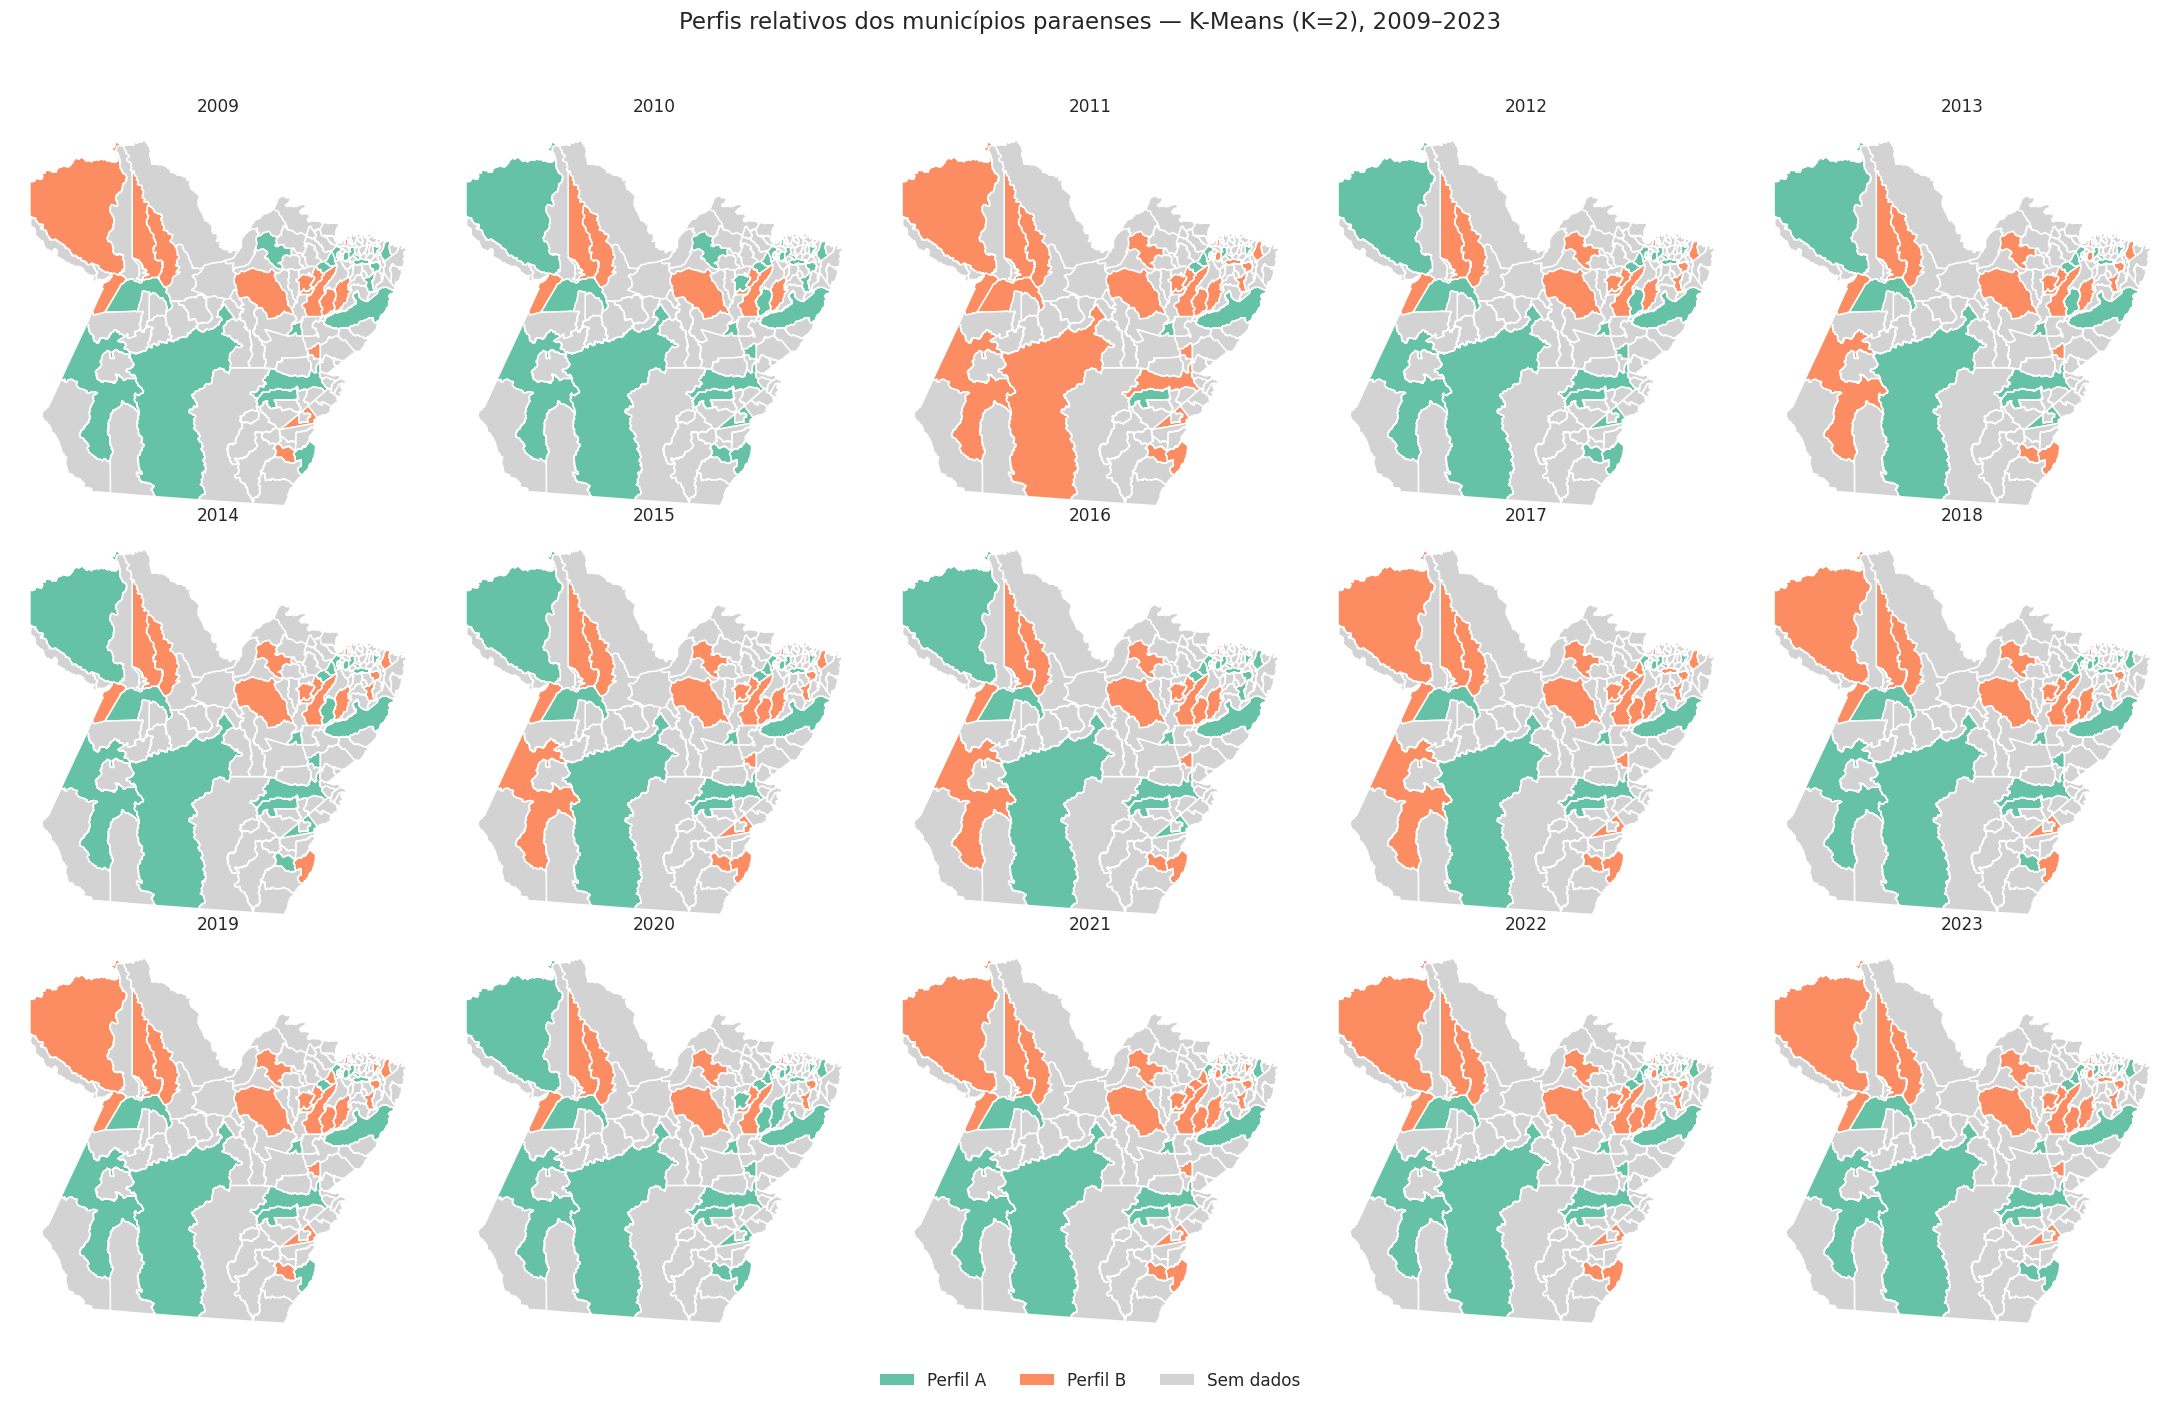

In [11]:
# =============================================================
# MAPAS DOS PERFIS MUNICIPAIS — 2009 A 2023
# =============================================================

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

mapas_gerados = []
# Os geodados municipais são carregados por read_allfiles2.
COLUNA_CODIGO_GEODADOS = "CD_MUN"
COLUNA_CODIGO_PAINEL = "CO_MUNICIPIO_TERRITORIO"

# Os geodados já foram carregados pela read_allfiles2 na célula 4.
geo = shape.copy()

# -------------------------------------------------------------
# 1. Validação e normalização dos códigos municipais
# -------------------------------------------------------------

if COLUNA_CODIGO_GEODADOS not in geo.columns:
    raise ValueError(
        f"Coluna {COLUNA_CODIGO_GEODADOS!r} não encontrada. "
        f"Colunas disponíveis: {list(geo.columns)}"
    )

if "geometry" not in geo.columns:
    raise ValueError("A base shape não contém a coluna geometry.")

def _codigo_texto(serie):
    """Normaliza códigos municipais IBGE para texto com sete dígitos."""
    return (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.replace(r"\D", "", regex=True)
        .str.zfill(7)
    )

geo["_codigo_municipio"] = _codigo_texto(
    geo[COLUNA_CODIGO_GEODADOS]
)

duplicados_geo = int(geo["_codigo_municipio"].duplicated().sum())

if duplicados_geo:
    raise ValueError(
        f"A base geográfica contém {duplicados_geo} códigos duplicados."
    )

# -------------------------------------------------------------
# 2. Preparação dos dados geográficos por edição
# -------------------------------------------------------------

#diretorio_mapas = DIRETORIO_SAIDA / "mapas"
#diretorio_mapas.mkdir(parents=True, exist_ok=True)

mapas_cluster = {}

for ano in ANOS:

    dados_cluster = classificacao_clusters.loc[
        classificacao_clusters["ano"].eq(ano),
        [COLUNA_CODIGO_PAINEL, "perfil_relativo"],
    ].copy()

    dados_cluster["_codigo_municipio"] = _codigo_texto(
        dados_cluster[COLUNA_CODIGO_PAINEL]
    )

    mapas_cluster[ano] = geo.merge(
        dados_cluster[
            ["_codigo_municipio", "perfil_relativo"]
        ],
        on="_codigo_municipio",
        how="left",
        validate="one_to_one",
    )

    n_classificados = mapas_cluster[ano]["perfil_relativo"].notna().sum()

    if n_classificados != len(dados_cluster):
        raise ValueError(
            f"Problema na associação geográfica de {ano}: "
            f"{n_classificados} municípios associados de "
            f"{len(dados_cluster)} classificados."
        )

# -------------------------------------------------------------
# 3. Quinze mapas dos perfis relativos — grade 3 x 5
# -------------------------------------------------------------

cores_perfis = plt.get_cmap("Set2").colors

cmap_perfis = ListedColormap([
    cores_perfis[0],
    cores_perfis[1],
])

legenda_perfis = [
    Patch(facecolor=cores_perfis[0], edgecolor="none", label="Perfil A"),
    Patch(facecolor=cores_perfis[1], edgecolor="none", label="Perfil B"),
    Patch(facecolor="lightgrey", edgecolor="none", label="Sem dados"),
]

fig, axes = plt.subplots(3, 5, figsize=(20, 13))

for ax, ano in zip(axes.flat, ANOS):

    mapas_cluster[ano].plot(
        column="perfil_relativo",
        categorical=True,
        cmap=cmap_perfis,
        legend=False,
        missing_kwds={"color": "lightgrey"},
        ax=ax,
    )

    ax.set_title(str(ano), fontsize=11)
    ax.set_axis_off()

fig.legend(
    handles=legenda_perfis,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.015),
)

fig.suptitle(
    f"Perfis relativos dos municípios paraenses — "
    f"K-Means (K={K_ESCOLHIDO}), 2009–2023",
    fontsize=15,
    y=0.99)

fig.tight_layout(rect=[0, 0.045, 1, 0.96])

plt.show()
plt.close(fig)

## ANEXO B-EXPORTAÇAO DOS RESULTADOS


In [12]:
DIRETORIO_SAIDA = (Path(PROJECT_ROOT) / "data" / "reports" / "clustering_aplicacao"/ f"uf={UF_PROCESSAMENTO}" / f"ref={TIPO_REFERENCIA}")
DIRETORIO_SAIDA.mkdir(parents=True, exist_ok=True)
arquivos_saida = {
    "classificacao_municipios_kmeans_k2_2009_2023.csv": classificacao_clusters,
    "diagnostico_kmeans_k2_2009_2023.csv": diagnostico_clusters,
    "distribuicao_perfis_kmeans_k2_2009_2023.csv": distribuicao_perfis,
    "perfil_multidisciplinar_padronizado_k2_2009_2023.csv": perfil_z_anual,
    "medias_disciplinas_perfil_k2_2009_2023.csv": perfil_notas,
    "transicoes_municipais_k2_2009_2023.csv": transicoes_municipios,
    "matriz_transicao_k2_2009_2023.csv": matriz_transicoes,
    "painel_balanceado_k2_2009_2023.csv": painel_balanceado,
}

for nome, tabela in arquivos_saida.items():
    tabela.to_csv(DIRETORIO_SAIDA / nome, sep=";", index=False, encoding="utf-8-sig")

print(f"{len(arquivos_saida)} arquivos exportados para: {DIRETORIO_SAIDA}")

8 arquivos exportados para: /home/akel/PycharmProjects/Projeto_ENEM/data/reports/clustering_aplicacao/uf=PA/ref=ESC
